# Building an optimal portfolio system

1) Forecast (the big one)
2) Risk model (start with sample covariance matrix)
3) Cost model (start with only spread)

## Gathering Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[2] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../../../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
START = "2025-06-02"
END = "2026-06-02"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11)
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 59acd1f31c5cb651598f2b52e55c5b57.parquet
[GenericAdapter] scan_parquet: ae6e2e353449ba87c7db99ba2b04787b.parquet
[GenericAdapter] scan_parquet: 5ad4fa3280634d57059736634fa2bfe8.parquet


In [2]:
# daily volume before the final 10mins
session_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("SDV")
    )
    .sort("date")
)

avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).alias("ADV")
    )
    .drop("day_volume")
    .sort("date")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (
            (pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)
        ).alias("spread_return")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["price", "spread_return"]).last()
    )
    .rename({"price":"entry_price"})
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty"]).first()
    )
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(session_dollar_volume, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .drop_nulls()
    .with_columns((pl.col("total_imbalance_qty") * pl.col("entry_price")).alias("dollar_imbalance"))
    .with_columns(
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("SDV"))
        ).alias("signed_session_imb_ratio"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("ADV"))
        ).alias("signed_mean_imb_ratio")
    )
    .drop(["total_imbalance_qty"])
).collect(engine="streaming")

# The dataframe we will be working with
data

date,symbol,side,entry_price,spread_return,auction_price,SDV,ADV,dollar_imbalance,signed_session_imb_ratio,signed_mean_imb_ratio
date,cat,str,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-02,"""AAL""","""B""",11.335,0.000882,11.38,4.2328e7,2.2967e7,6.2903e6,0.148609,0.273888
2025-06-02,"""AAOI""","""A""",15.61,0.00064,15.515,5.9566e6,2.3829e7,351786.96,-0.059058,-0.014763
2025-06-02,"""AAON""","""A""",93.74,0.000533,94.07,8.4558e6,5.1814e7,734452.9,-0.086858,-0.014175
2025-06-02,"""AAPL""","""A""",201.59,0.00005,201.7,1.5063e9,3.1558e8,1.6576e8,-0.110046,-0.525258
2025-06-02,"""AAXJ""","""N""",78.155,0.000128,78.21,6.2205e6,1.3742e7,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…
2026-06-01,"""ZM""","""B""",111.21,0.00018,111.62,1.7346e8,8.3016e7,1.2752e7,0.073518,0.153612
2026-06-01,"""ZNTL""","""A""",3.995,0.002503,3.98,684972.53,5.3082e6,1114.605,-0.001627,-0.00021
2026-06-01,"""ZS""","""A""",157.45,0.001652,155.71,2.5789e8,7.6015e8,1.0252e7,-0.039753,-0.013487


## Forecast
OLS regression of qty_signal on returns from 3:50:00 to close. Had an R^2 of 0.0512 (from rules_based_backtest.ipynb)

In [4]:
import statsmodels.api as sm
study_data = data.filter(pl.col("dollar_imbalance") >= 500_000).with_columns((pl.col("auction_price") / pl.col("entry_price") - 1).alias("return_to_close"))
# X = sm.add_constant(study_data['signed_mean_imb_ratio'].to_numpy()) # debating whether to add .clip(-1,1)
X = study_data['signed_mean_imb_ratio'].to_numpy() # debating whether to add .clip(-1,1)

y = (study_data['return_to_close']).to_numpy()

res = sm.OLS(y, X).fit()

# print(res.summary())
print(f'beta   = {res.params[0]:+.5f}')
# print(f'beta_1  = {res.params[1]:+.5f}')
print(f'R^2     = {res.rsquared:.4f}')
print(f't(beta) = {res.tvalues[0]:+.2f}')

beta   = +0.00208
R^2     = 0.0205
t(beta) = +52.29


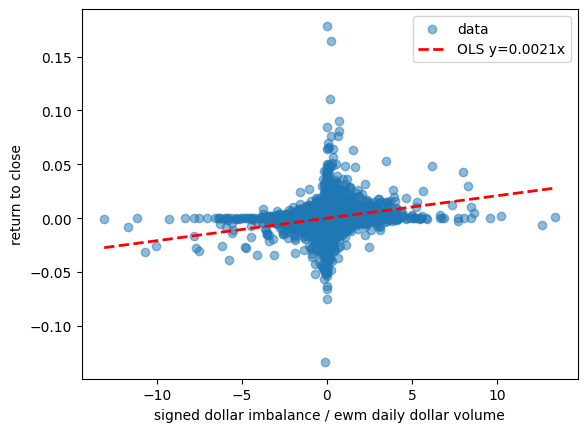

In [5]:
xs = np.linspace(np.min(X), np.max(X)).clip()
plt.scatter(X, y, alpha=0.5, label="data")
plt.plot(xs, res.params[0] * xs, label=f'OLS y={res.params[0]:,.4f}x', color='red', linestyle='--', linewidth=2)
plt.xlabel("signed dollar imbalance / ewm daily dollar volume")
plt.ylabel("return to close")
plt.legend()
plt.show()

In [6]:
from scipy.stats import spearmanr

ic, pval = spearmanr(X, y)
print(f"Spearman IC for ewm daily dollar volume: {ic:,.3f} with p-value: {pval:,.3f}")

Spearman IC for ewm daily dollar volume: 0.250 with p-value: 0.000


## Risk (Covariance) Model
Starting with a **SIMPLE** sample covariance of daily returns, filling null daily returns with the symbols **MEAN**.

Very much not a good enough covariance matrix yet.

In [7]:
daily_ret = (
    df_trades
    .select(["ts_event", "symbol", "price"])
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"])
    .agg(
        pl.col("price").last()
    )
    .sort("date")
    .with_columns(
        pl.col("price").pct_change().over("symbol").alias("ret")
    )
    .pivot(
        on="symbol",
        on_columns=data['symbol'].unique().sort().to_list(),
        index="date",
        values="ret"
    )
    .with_columns(
        pl.all().fill_null(pl.all().mean())
    )
)

daily_ret = daily_ret.collect(engine="streaming")
daily_ret

date,AAL,AAOI,AAON,AAPL,AAXJ,ABAT,ABCL,ABNB,ABSI,ABUS,ABVX,ACAD,ACB,ACGL,ACHC,ACIW,ACLS,ACMR,ACRS,ACT,ACWI,ACWX,ADAM,ADBE,ADEA,ADI,ADMA,ADP,ADPT,ADSK,ADTN,ADUS,AEHR,AEIS,AEP,AEVA,…,WSFS,WTFC,WTW,WULF,WVE,WWD,WYFI,WYNN,XBCI,XE,XEL,XELLL,XENE,XERS,XLP,XLV,XMTR,XNCR,XNDU,XOVR,XP,XPEL,XRAY,XRX,YSWY,Z,ZBIO,ZBRA,ZD,ZG,ZION,ZLAB,ZM,ZNTL,ZS,ZVRA,ZYME
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-02 00:00:00,0.001409,0.01344,0.002309,0.001768,0.001871,0.006948,0.005656,0.000417,0.005215,0.001556,0.028414,0.000279,-0.000479,-0.000239,0.001125,0.000111,0.004568,0.006229,0.00599,0.000741,0.001012,0.001036,0.001308,-0.001323,0.003954,0.002686,-0.003183,-0.001212,0.002703,-0.000487,0.003865,-0.000679,0.011721,0.004241,0.000794,0.004491,…,0.00133,0.000963,-0.000688,0.009917,0.003874,0.002038,0.006166,0.001025,-0.001375,-0.001453,0.000438,-0.00024,0.002892,0.001376,-0.00001,0.000472,0.005882,0.002089,0.028895,0.000627,-0.000227,0.001216,-0.001391,-0.000242,0.002825,-0.002143,0.005142,-0.000199,0.002372,-0.002073,0.001241,-0.001787,0.001595,0.00738,-0.001803,0.001839,0.003521
2025-06-03 00:00:00,0.008795,0.081883,0.015836,0.007731,0.00211,0.061151,0.079439,0.025536,0.027624,0.026826,0.220565,0.023288,0.03071,-0.004778,0.03791,0.014524,0.049973,0.025934,0.02439,-0.002859,0.002087,-0.004325,0.001308,0.022509,0.031151,0.013783,0.001957,0.002179,0.040838,0.014427,-0.016588,0.012769,0.061077,0.028307,-0.003199,0.138985,…,0.020439,0.02366,-0.010969,0.046961,0.0432,0.058602,0.006166,-0.000456,-0.001375,-0.001453,-0.005881,-0.00024,0.022311,-0.075397,-0.001146,0.001996,0.052624,0.065889,0.028895,0.008366,-0.007696,0.040045,0.0176,0.032025,0.002825,0.011266,-0.044821,0.021123,0.038251,0.010098,0.028109,-0.002563,-0.00406,0.070313,0.006481,0.025434,0.036021
2025-06-04 00:00:00,-0.004359,0.01907,0.000314,-0.002557,0.014293,0.030508,0.049784,0.004363,0.023297,-0.011611,0.03537,-0.009103,0.035382,-0.011375,0.006236,-0.00406,0.038143,-0.01114,0.091837,-0.006594,0.002563,0.0071,0.001308,0.003515,0.002677,0.000137,-0.007813,-0.001011,0.004024,-0.003906,-0.012048,-0.006082,0.140488,0.009344,-0.009725,0.038481,…,-0.022569,-0.020336,-0.014023,0.116095,0.023006,0.01651,0.006166,-0.018236,-0.001375,-0.001453,-0.011831,-0.00024,-0.006515,-0.050429,-0.006765,0.00218,-0.011514,-0.00547,0.028895,0.004978,0.01241,-0.024502,0.01195,0.009009,0.002825,0.016059,-0.004171,-0.003733,0.012693,0.017054,-0.014499,0.159332,-0.003335,0.09854,0.005693,0.006764,0.009106
2025-06-05 00:00:00,-0.013135,-0.050877,-0.007949,-0.011192,0.005033,-0.039474,-0.024742,0.028387,-0.005254,0.0,0.013043,-0.020211,-0.027878,-0.002006,0.002213,0.007724,-0.019021,0.02383,-0.034268,-0.008369,-0.003036,0.000664,0.001308,0.003068,0.015256,-0.002288,-0.018701,-0.000061,-0.011022,-0.000804,-0.031707,0.001385,-0.05432,-0.001918,-0.000491,-0.070697,…,-0.001924,-0.008754,-0.005301,-0.095745,0.012744,-0.005329,0.006166,-0.033782,-0.001375,-0.001453,0.001606,-0.00024,0.006557,0.00791,-0.009425,-0.000938,0.041581,0.0033,0.028895,-0.005504,0.009704,0.009661,-0.01243,-0.009921,0.002825,-0.005696,0.00733,0.0011,0.003057,-0.003614,0.002102,0.012746,0.00818,-0.026578,0.013883,-0.011758,-0.005742
2025-06-06 00:00:00,0.043478,0.036661,0.019926,0.016854,0.003881,0.003425,0.035941,0.024472,0.065141,0.020558,0.001839,0.030474,0.058279,0.010366,0.004196,0.006813,0.053696,0.045281,-0.009677,0.006985,0.007853,0.003647,0.001308,0.003709,0.006011,0.01968,0.033601,0.001778,0.02229,-0.001023,0.011335,0.011418,0.024876,0.014874,0.0,0.096013,…,0.023713,0.023213,0.004517,0.135948,0.070318,0.005486,0.006166,0.00036,-0.001375,-0.001453,-0.001458,-0.00024,0.030619,0.025785,0.002824,0.008935,0.040487,0.058114,0.028895,0.014942,-0.003035,0.011755,0.003461,0.03006,0.00282

In [8]:
cov_matrix = np.cov(daily_ret.drop("date").to_numpy(), rowvar=False)
cov_matrix

array([[ 9.66433910e-04,  2.28810169e-04,  4.74309892e-04, ...,
         5.36143712e-05,  1.22128798e-04,  1.26394539e-04],
       [ 2.28810169e-04,  7.42639163e-03,  6.96246408e-04, ...,
        -3.10108154e-04,  2.77270713e-04,  1.24427473e-04],
       [ 4.74309892e-04,  6.96246408e-04,  1.57702085e-03, ...,
         8.43160380e-05,  6.83643320e-06, -7.38317086e-05],
       ...,
       [ 5.36143712e-05, -3.10108154e-04,  8.43160380e-05, ...,
         1.33015150e-03, -3.40018285e-05,  1.14514446e-04],
       [ 1.22128798e-04,  2.77270713e-04,  6.83643320e-06, ...,
        -3.40018285e-05,  1.41459833e-03,  2.00343437e-04],
       [ 1.26394539e-04,  1.24427473e-04, -7.38317086e-05, ...,
         1.14514446e-04,  2.00343437e-04,  1.12292116e-03]],
      shape=(1319, 1319))

## Daily MVO Optimizer

In [9]:
import cvxpy as cp

class ForecastModel:
    """Maps a day's features -> dense alpha vector aligned to `universe`. Missing names -> 0."""
    def __init__(self, universe, beta_1):
        self.universe = universe
        self.sym_idx_map = {s: i for i, s in enumerate(universe)}
        self.beta_1 = beta_1
    
    def get_alpha(self, day_df: pl.DataFrame) -> np.ndarray:
        """Gets the forecast mean return using beta_1. Does not include an intercept, so that 0 signal gets 0 forecast."""
        alpha = np.zeros(len(self.universe))
        for symbol, signal in zip(day_df['symbol'], day_df["signed_mean_imb_ratio"]):
            alpha[self.sym_idx_map[symbol]] = self.beta_1 * signal
        return alpha

class CostModel:
    """Half-spread (in return space) per name; names with no quote -> large cost so the optimizer avoids them."""
    def __init__(self, universe: list, commission: float):
        self.universe = universe
        self.commission = commission
        self.sym_idx_map = {s:i for i, s in enumerate(universe)}
    
    def get_cost(self, day_df: pl.DataFrame) -> np.ndarray:
        cost = np.zeros(len(self.universe))
        for symbol, spread in zip(day_df["symbol"], day_df["spread_return"]):
            cost[self.sym_idx_map[symbol]] = spread * 0.5 + self.commission
        return cost

class Optimizer:
    """Single-Period Daily MVO system."""
    def __init__(self, universe: list):
        self.universe = universe
        self.N = len(universe)
        
    def set_problem(self, Sigma: np.ndarray, lam: float):
        self.w = cp.Variable(self.N)
        self.alpha = cp.Parameter(self.N)
        self.cost = cp.Parameter(self.N, nonneg=True)
        self.Sigma = cp.psd_wrap(cp.Constant(Sigma))

        self.objective = cp.Maximize(
            self.alpha @ self.w
            - (lam/2) * cp.quad_form(self.w, self.Sigma)
            - (self.cost/2) @ cp.abs(self.w)
        )
        self.constraints = [
            cp.abs(cp.sum(self.w)) <= 1e-4,
            cp.norm(self.w, 1) <= 1,
            cp.abs(self.w) <= 0.10
        ]
        self.problem = cp.Problem(self.objective, self.constraints)
    
    def solve(self, alpha, cost) -> np.ndarray:
        self.alpha.value = alpha
        self.cost.value = cost
        self.problem.solve(warm_start=True)
        if self.problem.status not in ("optimal", "optimal_inaccurate"):
            raise RuntimeError(self.problem.status)
        return self.w.value

In [10]:
SYMBOLS = daily_ret.columns[1:]

opt = Optimizer(SYMBOLS)
opt.set_problem(Sigma=cov_matrix, lam=1)
f_model = ForecastModel(SYMBOLS, beta_1 = res.params[0])
c_model = CostModel(SYMBOLS, commission=0.0035)

# weights = {}
# for d in data["date"].to_list():
#     day_df = data.filter(pl.col("date") == d)

#     alpha = f_model.get_alpha(day_df)
#     cost = c_model.get_cost(day_df)
#     ws = opt.solve(alpha, cost)
#     weights[d] = {s:w for s,w in zip(SYMBOLS, ws)}

In [11]:
# # Optimizer weights over time, one line per symbol (only names ever held)
# dates = sorted(weights.keys())
# label_thresh = 0.005  # a symbol is "held" if |weight| exceeds this on some day

# held = sorted({s for d in dates for s, wv in weights[d].items() if abs(wv) > label_thresh})

# fig, ax = plt.subplots(figsize=(16, 8))
# for s in held:
#     series = [weights[d].get(s, 0.0) for d in dates]
#     ax.plot(dates, series, lw=0.8, alpha=0.7)
#     # label at the symbol's last meaningful point
#     last_idx = max(i for i, v in enumerate(series) if abs(v) > label_thresh)
#     ax.annotate(s, (dates[last_idx], series[last_idx]), fontsize=7)

# ax.axhline(0, color="grey", lw=0.5)
# ax.set_xlabel("date")
# ax.set_ylabel("weight")
# ax.set_title(f"Optimizer weights over time (|w| > {label_thresh} on some day)  —  {len(held)} names")
# fig.tight_layout()
# plt.show()

## Parallel daily solve

Each trading day is an independent QP (the book is flat at every close), so the days fan out across processes with `joblib`'s `loky` backend (works with notebook-defined classes via cloudpickle). Each worker compiles the parametrized problem **once** and warm-starts through a contiguous chunk of days — so compile cost is paid `N_JOBS` times, not once per day. Produces `weights` in the same `{date: {symbol: w}}` shape as the serial loop, so the over-time plot above works unchanged: run this cell, then re-run the plot.

In [12]:
# --- Parallel daily solve (days are independent; book is flat at every close) ---
# Fans the days across processes. Each worker compiles the parametrized QP ONCE
# and warm-starts through a contiguous chunk of days. Produces `weights` in the
# same {date: {symbol: w}} shape as the serial loop, so the over-time plot works
# unchanged. Run AFTER f_model / c_model / SYMBOLS / cov_matrix are defined.
import os
from joblib import Parallel, delayed

N_JOBS = max(1, os.cpu_count() - 2)
LAM = 1.0

def _solve_chunk(symbols, Sigma, lam, day_records):
    """One worker: compile the QP once, then warm-start through its chunk of days."""
    opt = Optimizer(symbols)
    opt.set_problem(Sigma=Sigma, lam=lam)        # compile paid once per worker, not per day
    return [(date, opt.solve(alpha, cost)) for date, alpha, cost in day_records]

def _split_contiguous(items, n):
    """Contiguous chunks so adjacent days share a worker -> warm_start actually helps."""
    k, m = divmod(len(items), n)
    return [items[i * k + min(i, m):(i + 1) * k + min(i + 1, m)] for i in range(n)]

# Build per-day (alpha, cost) in the parent (cheap, vectorized) so workers receive
# only small 1-D arrays; cov_matrix is auto-memmapped by loky and shared read-only.
all_dates = data["date"].unique().sort().to_list()
day_records = [
    (d, f_model.get_alpha(day), c_model.get_cost(day))
    for d in all_dates
    for day in [data.filter(pl.col("date") == d)]
]

chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
    delayed(_solve_chunk)(SYMBOLS, cov_matrix, LAM, chunk) for chunk in chunks
)

weights = {d: dict(zip(SYMBOLS, ws)) for chunk in chunk_results for d, ws in chunk}
print(f"solved {len(weights)} days across {len(chunks)} workers")

/Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/.venv/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


solved 248 days across 12 workers


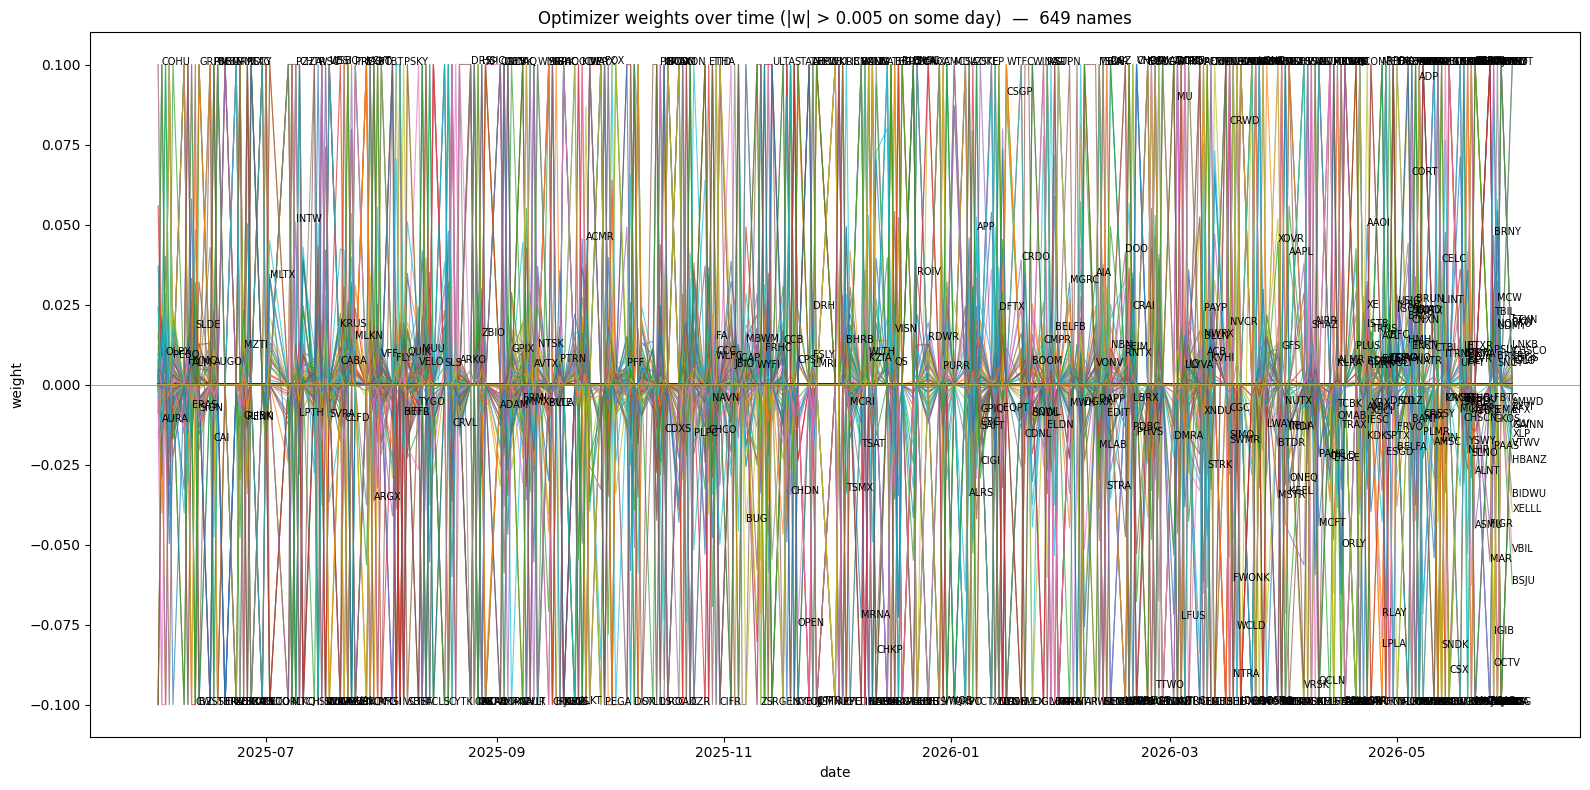

In [13]:
# Optimizer weights over time, one line per symbol (only names ever held)
dates = sorted(weights.keys())
label_thresh = 0.005  # a symbol is "held" if |weight| exceeds this on some day

held = sorted({s for d in dates for s, wv in weights[d].items() if abs(wv) > label_thresh})

fig, ax = plt.subplots(figsize=(16, 8))
for s in held:
    series = [weights[d].get(s, 0.0) for d in dates]
    ax.plot(dates, series, lw=0.8, alpha=0.7)
    # label at the symbol's last meaningful point
    last_idx = max(i for i, v in enumerate(series) if abs(v) > label_thresh)
    ax.annotate(s, (dates[last_idx], series[last_idx]), fontsize=7)

ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("date")
ax.set_ylabel("weight")
ax.set_title(f"Optimizer weights over time (|w| > {label_thresh} on some day)  —  {len(held)} names")
fig.tight_layout()
plt.show()

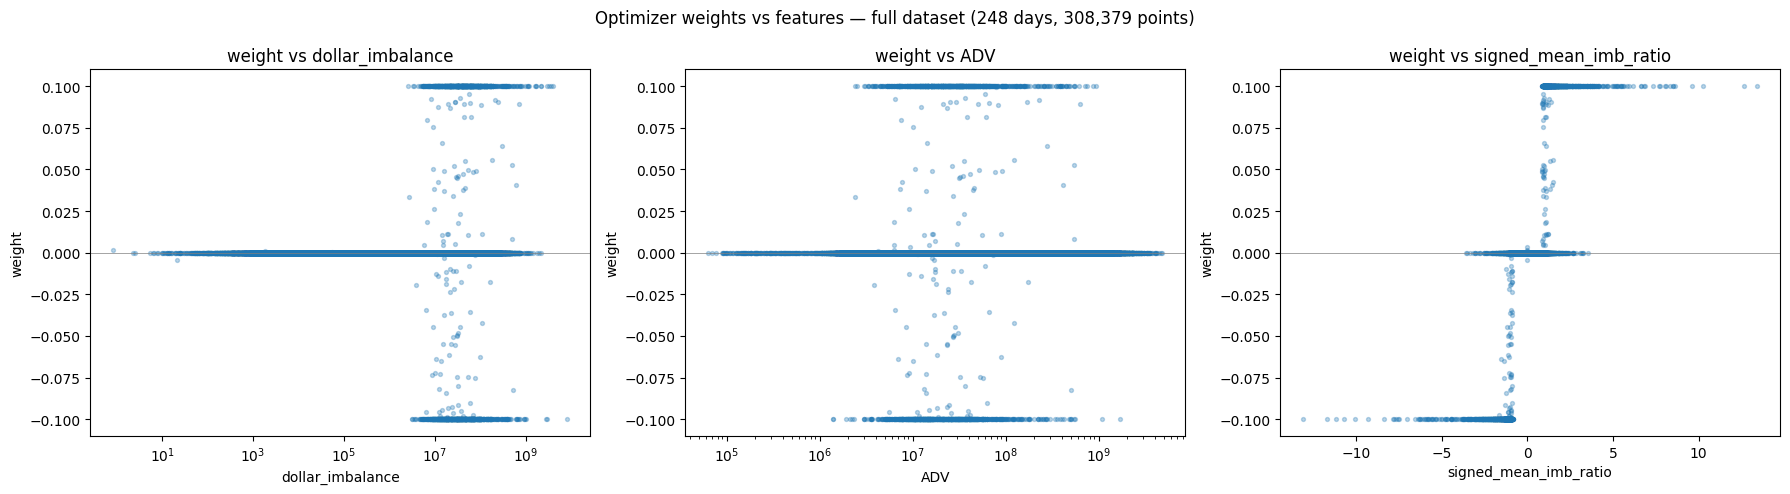

In [16]:
# Scatter weights vs day features over the FULL dataset (all dates pooled)
# Flatten {date: {symbol: w}} -> long frame, then join each day's features from `data`.
w_long = pl.DataFrame(
    {
        "date": [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }
).with_columns(pl.col("symbol").cast(pl.Categorical))

plot_df = data.join(w_long, on=["date", "symbol"], how="inner")

weights_arr = plot_df["weight"].to_numpy()
features = ["dollar_imbalance", "ADV", "signed_mean_imb_ratio"]
log_x = {"dollar_imbalance", "ADV"}   # positive, span orders of magnitude; signed ratio stays linear

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat in zip(axes, features):
    x = plot_df[feat].to_numpy()
    ax.scatter(x, weights_arr, alpha=0.3, s=8)
    ax.axhline(0, color="grey", lw=0.5)
    if feat in log_x:
        ax.set_xscale("log")
    ax.set_xlabel(feat)
    ax.set_ylabel("weight")
    ax.set_title(f"weight vs {feat}")

fig.suptitle(f"Optimizer weights vs features — full dataset ({len(weights)} days, {len(plot_df):,} points)")
fig.tight_layout()
plt.show()

## Accountant

Turns the optimizer `weights` (`{date: {symbol: w}}`) into a trade ledger and PnL/risk report.

- **Capital:** `CAPITAL` is deployed each day; weights are read as **dollar fractions**, so name *i*'s position is `w_i · CAPITAL` (gross `||w||₁·CAPITAL ≤ CAPITAL`).
- **Execution:** enter at 15:50 (`entry_price`), exit in the **closing auction** (`auction_price`).
- **Costs:** pay **half the quoted spread on entry only** (we cross once getting in; the auction print has no spread), and **commission both ways** (`COMMISSION_PER_SHARE` per share on each leg).
- **Output:** `trades` (per name/day) → `daily` (per-day PnL, equity, drawdown) → Sharpe, max drawdown, hit rate, and the equity curve.

In [23]:
# ----- Accountant inputs -----
CAPITAL = 1_000_000            # capital deployed each day; weights are dollar fractions (||w||_1 <= 1)
COMMISSION_PER_SHARE = 0.0035  # $/share, charged on BOTH entry and exit (round trip)
MIN_WEIGHT = 0              # ignore optimizer "dust" weights

# Flatten {date: {symbol: w}} -> long, then join the day's execution prices/spread from `data`.
w_long = pl.DataFrame(
    {
        "date":   [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }
).with_columns(pl.col("symbol").cast(pl.Categorical))

# Entry @ 15:50 (entry_price), exit @ closing auction (auction_price).
# Costs: half the quoted spread on ENTRY only; commission per share on BOTH legs.
trades = (
    data
    .join(w_long, on=["date", "symbol"], how="inner")
    .filter(pl.col("weight").abs() > MIN_WEIGHT)
    .with_columns(
        (pl.col("weight") * CAPITAL).alias("dollar_pos"),                  # signed $ position
        (pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("asset_ret"),
    )
    .with_columns((pl.col("dollar_pos") // pl.col("entry_price")).alias("shares"))  # signed
    .with_columns(
        (pl.col("dollar_pos") * pl.col("asset_ret")).alias("gross_pnl"),
        (pl.col("dollar_pos").abs() * pl.col("spread_return").clip(lower_bound=0.0) / 2.0).alias("spread_cost"),
        (pl.col("shares").abs() * COMMISSION_PER_SHARE * 2.0).alias("commission_cost"),
    )
    .with_columns(
        (pl.col("gross_pnl") - pl.col("spread_cost") - pl.col("commission_cost")).alias("net_pnl")
    )
    .select([
        "date", "symbol", "side", "weight", "dollar_pos", "shares",
        "entry_price", "auction_price", "asset_ret",
        "gross_pnl", "spread_cost", "commission_cost", "net_pnl",
    ])
    .sort(["date", "symbol"])
)
trades

date,symbol,side,weight,dollar_pos,shares,entry_price,auction_price,asset_ret,gross_pnl,spread_cost,commission_cost,net_pnl
date,cat,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-02,"""AAL""","""B""",-1.2917e-9,-0.001292,-1.0,11.335,11.38,0.00397,-0.000005,5.6978e-7,0.007,-0.007006
2025-06-02,"""AAOI""","""A""",1.5201e-8,0.015201,0.0,15.61,15.515,-0.006086,-0.000093,0.000005,0.0,-0.000097
2025-06-02,"""AAON""","""A""",-1.6820e-9,-0.001682,-1.0,93.74,94.07,0.00352,-0.000006,4.4847e-7,0.007,-0.007006
2025-06-02,"""AAPL""","""A""",-6.1959e-9,-0.006196,-1.0,201.59,201.7,0.000546,-0.000003,1.5368e-7,0.007,-0.007004
2025-06-02,"""AAXJ""","""N""",-2.1608e-9,-0.002161,-1.0,78.155,78.21,0.000704,-0.000002,1.3824e-7,0.007,-0.007002
…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-01,"""ZM""","""B""",2.8487e-9,0.002849,0.0,111.21,111.62,0.003687,0.000011,2.5616e-7,0.0,0.00001
2026-06-01,"""ZNTL""","""A""",1.4139e-8,0.014139,0.0,3.995,3.98,-0.003755,-0.000053,0.000018,0.0,-0.000071
2026-06-01,"""ZS""","""A""",8.9623e-9,0.008962,0.0,157.45,155.71,-0.011051,-0.000099,0.000007,0.0,-0.000106


Days traded:        248
Capital / day:      $1,000,000   (avg gross exposure $656,873 = 66%)
Total net PnL:      $166,058
Cumulative return:  +17.99%
Ann. return:        +16.87%
Ann. volatility:    3.49%
Sharpe (ann):       4.84
Max drawdown:       -0.62%
Daily hit rate:     60.9%
Total commission:   $15,529
Total spread cost:  $40,438


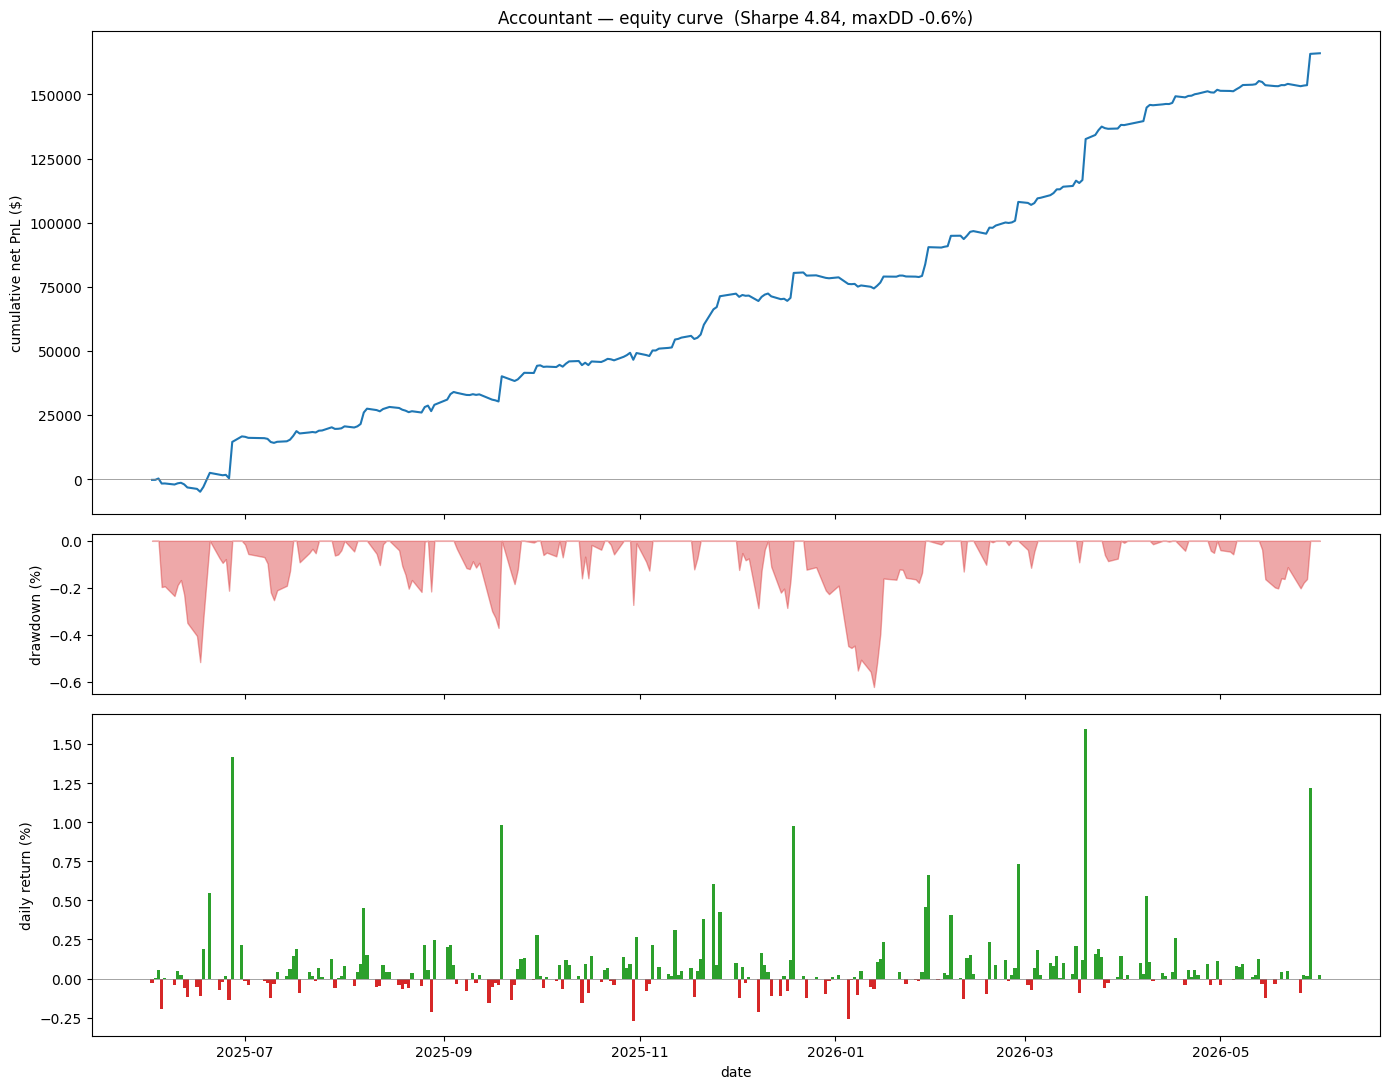

date,gross_pnl,spread_cost,commission_cost,net_pnl,gross_exposure,n_positions,ret,cum_pnl,equity,drawdown
date,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64
2025-06-02,-217.476984,43.46299,52.206,-313.145974,600033.663267,1207,-0.000313,-313.145974,0.999687,0.0
2025-06-03,315.386334,170.96469,123.487,20.934644,500052.091239,1209,0.000021,-292.21133,0.999708,0.0
2025-06-04,650.295477,94.608436,37.611,518.076042,600047.880613,1203,0.000518,225.864711,1.000226,0.0
2025-06-05,-1802.368406,112.061199,49.315,-1963.744605,600108.377872,1202,-0.001964,-1737.879894,0.998262,-0.001964
2025-06-06,102.318499,49.023447,23.807,29.488051,200067.980896,1201,0.000029,-1708.391842,0.998291,-0.001934
…,…,…,…,…,…,…,…,…,…,…
2026-05-26,-475.432266,237.828451,187.355,-900.615717,999924.938167,1282,-0.000901,153215.53193,1.164907,-0.002019
2026-05-27,302.441006,30.331806,25.942,246.167201,300173.803496,1279,0.000246,153461.699131,1.165194,-0.001774
2026-05-28,363.045691,154.180114,59.626,149.239576,600061.399231,1282,0.000149,153610.938707,1.165368,-0.001625


In [24]:
# Daily PnL, equity curve, and risk/return metrics
ANN = 252  # trading days for annualization

daily = (
    trades
    .group_by("date")
    .agg(
        pl.col("gross_pnl").sum(),
        pl.col("spread_cost").sum(),
        pl.col("commission_cost").sum(),
        pl.col("net_pnl").sum(),
        pl.col("dollar_pos").abs().sum().alias("gross_exposure"),
        pl.len().alias("n_positions"),
    )
    .sort("date")
    .with_columns((pl.col("net_pnl") / CAPITAL).alias("ret"))   # return on the daily capital base
    .with_columns(
        pl.col("net_pnl").cum_sum().alias("cum_pnl"),
        (1.0 + pl.col("ret")).cum_prod().alias("equity"),       # growth of $1 (compounded)
    )
    .with_columns((pl.col("equity") / pl.col("equity").cum_max() - 1.0).alias("drawdown"))
)

# --- summary metrics ---
rets = daily["ret"].to_numpy()
sharpe   = rets.mean() / rets.std(ddof=1) * np.sqrt(ANN)
ann_ret  = rets.mean() * ANN
ann_vol  = rets.std(ddof=1) * np.sqrt(ANN)
total_pnl = daily["net_pnl"].sum()
cum_ret  = daily["equity"][-1] - 1.0
max_dd   = daily["drawdown"].min()
hit_rate = float((rets > 0).mean())

print(f"Days traded:        {len(daily)}")
print(f"Capital / day:      ${CAPITAL:,.0f}   (avg gross exposure ${daily['gross_exposure'].mean():,.0f} = {daily['gross_exposure'].mean()/CAPITAL:.0%})")
print(f"Total net PnL:      ${total_pnl:,.0f}")
print(f"Cumulative return:  {cum_ret:+.2%}")
print(f"Ann. return:        {ann_ret:+.2%}")
print(f"Ann. volatility:    {ann_vol:.2%}")
print(f"Sharpe (ann):       {sharpe:.2f}")
print(f"Max drawdown:       {max_dd:.2%}")
print(f"Daily hit rate:     {hit_rate:.1%}")
print(f"Total commission:   ${daily['commission_cost'].sum():,.0f}")
print(f"Total spread cost:  ${daily['spread_cost'].sum():,.0f}")

# --- equity curve + drawdown + daily return bars ---
dts = daily["date"].to_list()
bar_colors = np.where(rets >= 0, "tab:green", "tab:red")

fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1, figsize=(14, 11), sharex=True, height_ratios=[3, 1, 2]
)
ax1.plot(dts, daily["cum_pnl"].to_numpy(), color="tab:blue")
ax1.axhline(0, color="grey", lw=0.5)
ax1.set_ylabel("cumulative net PnL ($)")
ax1.set_title(f"Accountant — equity curve  (Sharpe {sharpe:.2f}, maxDD {max_dd:.1%})")

ax2.fill_between(dts, daily["drawdown"].to_numpy() * 100, 0, color="tab:red", alpha=0.4)
ax2.set_ylabel("drawdown (%)")

ax3.bar(dts, rets * 100, color=bar_colors, width=1.0)
ax3.axhline(0, color="grey", lw=0.5)
ax3.set_ylabel("daily return (%)")
ax3.set_xlabel("date")

fig.tight_layout()
plt.show()

daily

### Notes

1. Covariance matrix is crap at the moment.
    - We need way more daily data
    - We need to use a factor-structure, and add a market-neutrality constraint
    - We need to be doing some shrinkage
    - We need to plot GMV (gross exposure above) against different values of the risk-aversion parameter lambda.
2. The forecast is ok but also probably crap.
    - We need to think creatively about using more features. they may be weaker individually, but powerful in interaction wiht teh stronger imbalance signal.
    - This may allow us to use lasso, or maybe a random forest.
3. Need to look over what Claude wrote (parallelization, accountant, plotting) to understand adn make changes.
4. Once these things are worked out:
    - Try continuous trading version from 15:50-15:55
    - Try shorter horizon from 15:55(ish)-16:00
    - Try multi-period from 15:50-15:55(ish), 15:55(ish)-16:00, or minutely from 15:00-16:00
    - Try combining the imbalance strategy with the overshoot into the morning auction.